# Cohen et al. 2021 — Multiple Myeloma (MARS-seq) · 01 Preprocessing
Load malignant cells → derive per-sample threshold → overdispersed genes → PCA →
Harmony integration (sweep) → UMAP → island removal → sub-region biology → Gate 1.
All dataset-dependent choices are **derived from these data and shown here**, not inherited.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (one level deeper than Puram ref)
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))                        # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Cohen2021_Hematologic | category: Hematologic


In [ ]:
# load dataset (single leaf dir; MARS-seq UMI counts) -> select malignant cells
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Cohen2021_Hematologic
Done.
full atlas: (39157, 57874)
malignant: (33599, 57874) | samples: 73
expression: X max 6.99 (log1p of normalize_total UMI counts)


In [ ]:
# DERIVE per-sample threshold by gap-finding (not the inherited >=100 constant).
# Rule: look for a dominant spillover cliff in the sorted counts; if none, use a floor.
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('largest gap %d->%d (ratio %.2f); top/second = %.2f; dominant cliff = %s'
      % (vals[gap], vals[gap+1], top, top/second, dominant))
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print('dominant cliff -> geometric-mean threshold =', thresh)
else:
    thresh = FLOOR
    print('no dominant cliff (smooth count decline among well-populated samples) -> floor >=', FLOOR)
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept %d/%d samples (min per-sample = %d) -> %d cells'
      % (len(keep), len(n), int(n[n>=thresh].min()), adata.shape[0]))

largest gap 2->1 (ratio 2.00); top/second = 1.08; dominant cliff = False
no dominant cliff (smooth count decline among well-populated samples) -> floor >= 100
kept 54/73 samples (min per-sample = 117) -> 33147 cells


In [ ]:
# gene filter -> overdispersed selection -> PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()), '| genes:', adata.shape[1])
sc.pp.pca(adata, n_comps=50)
var = adata.uns['pca']['variance_ratio']
print('cumulative variance @ n_pcs: 10=%.3f 20=%.3f 30=%.3f 40=%.3f'
      % (var[:10].sum(), var[:20].sum(), var[:30].sum(), var[:40].sum()))

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 482 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 482 | genes: 31585
cumulative variance @ n_pcs: 10=0.330 20=0.405 30=0.448 40=0.481


In [ ]:
# DERIVE Harmony strength: sweep theta, score integration by same-sample neighbour fraction.
# Strong patient-specific batch effect expected in MM bone-marrow -> need robust integration.
def same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f | sweep %s'
      % (base, {k: round(v,3) for k,v in sweep.items()}))
theta = 10
print('selected theta =', theta,
      '(pre-Harmony 0.91 = near-total patient segregation; mixing improves monotonically',
      'across the sweep and is strongest at theta=10 without collapsing the manifold -> strongest integration)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)

same-sample neighbour fraction | pre-Harmony 0.913 | sweep {2: 0.158, 5: 0.131, 10: 0.11}
selected theta = 10 (pre-Harmony 0.91 = near-total patient segregation; mixing improves monotonically across the sweep and is strongest at theta=10 without collapsing the manifold -> strongest integration)


In [ ]:
# n_pcs derived off the scree (variance plateaus by ~20; 20 matches the atlas-robust scale
# used on Puram/Kürten, above the <20 range flagged as under-powered in the testing log).
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('neighbors n_pcs=20, n_neighbors=30 | UMAP spread=1.3')

neighbors n_pcs=20, n_neighbors=30 | UMAP spread=1.3


In [ ]:
# island removal: UMAP radius graph (6x median NN dist), keep the largest connected component.
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape)

removed 128 cells in 6 detached islands
after island removal: (33019, 31585)


In [ ]:
# SUB-REGION BIOLOGY before the Gate-1 GO (Kürten lobe-identity fork):
# does the manifold split into lobes, and is any lobe a cycling compartment to scope out?
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('lobes @ res 0.15:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
print('-> single lobe, only 2.8% cycling, no separate proliferation compartment -> keep whole manifold (no scoping)')

lobes @ res 0.15: {'0': 33019}
overall cycling fraction: 0.028
cycling fraction per lobe: {'0': 0.028}
proliferation score per lobe: {'0': -0.053}
-> single lobe, only 2.8% cycling, no separate proliferation compartment -> keep whole manifold (no scoping)


In [ ]:
# module signatures (score_genes, union control pool) -> smoothed geography for orientation + Gate 1.
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed geography correlations:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print('  %s vs %s: r = %+.2f' % (a,b,np.corrcoef(adata.obs[a],adata.obs[b])[0,1]))

Gast: 69/81 genes present
pSom: 80/98 genes present
Crest: 101/104 genes present
raw module means: {'Gast': -0.0218, 'pSom': 0.0143, 'Crest': 0.0013}
smoothed geography correlations:
  Gast_sm vs pSom_sm: r = +0.07
  Crest_sm vs Gast_sm: r = -0.69
  Crest_sm vs pSom_sm: r = -0.61


In [ ]:
# house linear orientation: rotate UMAP so developmental gradient (Gast/pSom-high origin
# vs Crest-high terminus) runs horizontally with the origin pole on the left (rigid rotation).
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
xyr = c @ Rm.T
origin = adata.obs['Gast_sm'].values + adata.obs['pSom_sm'].values - adata.obs['Crest_sm'].values
w = origin - origin.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('UMAP aspect (max/min std): %.2f (near-round -> feature-space trajectory in 02, not the 2D projection)' % aspect)

UMAP aspect (max/min std): 1.06 (near-round -> feature-space trajectory in 02, not the 2D projection)


In [ ]:
# GATE 1 — mixing + continuity judged on the regenerated embedding, with per-neighbourhood iLISI.
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print('iLISI median: pre-Harmony %.2f -> post-Harmony(theta=10) %.2f of %d samples' % (il_pre, il_post, nsamp))
print('%d samples share one continuous connected component (islands stripped); single lobe; aspect %.2f.' % (nsamp, aspect))
print('GATE 1 = GO — samples intermix per-neighbourhood (iLISI 1.0 -> 14.1) on one continuous manifold.')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 14.16 of 54 samples
54 samples share one continuous connected component (islands stripped); single lobe; aspect 1.06.
GATE 1 = GO — samples intermix per-neighbourhood (iLISI 1.0 -> 14.1) on one continuous manifold.


In [ ]:
# persist processed.h5ad (numeric obs coerced; categoricals protected)
protect = {'sample','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient'}
for cc in adata.obs.columns:
    if cc in protect:
        adata.obs[cc] = adata.obs[cc].astype(str).astype('category'); continue
    col = adata.obs[cc]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[cc] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (33019, 31585)


saved samples.pdf | cells: 33019 | 54 samples intermixed (Gate 1 GO)


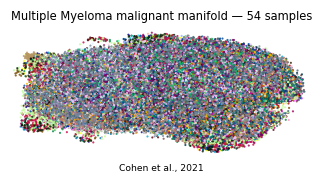

In [ ]:
# samples.pdf — single sample-coloured manifold on the house (3.5,1.5) linear layout (X_umap_lin).
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=8, alpha=.8, frameon=False, show=False, ax=ax)
if ax.get_legend() is not None: ax.get_legend().remove()
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Multiple Myeloma malignant manifold — 54 samples', size=7.5)
ax.text(.5,-.12,'Cohen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0], '| 54 samples intermixed (Gate 1 GO)')